# Part 2 — one controlled experiment: shared local temporal tokens

**Question:** does a temporal structure prior help attention generalize across people, rather than merely memorize 360 EEG trials?

**One bet:** eight 200 ms temporal filters shared across all electrodes, at 100 ms stride, produce 29 overlapping tokens plus CLS. The transformer backbone stays unchanged. Proposed model and vanilla each have **135,746 parameters**. Attention score entries fall **258×**, but measured speedup need not match that ratio.

**Four configurations:** Part-1-config EEGNet, unchanged vanilla transformer, proposed local-token model, and an equally sized scattered-time control. The control preserves the token count and learned weights but removes ordered contiguous grouping.

A well-controlled negative finding can satisfy the assessment. Higher accuracy is evidence, not the grading objective. Reduced variability from predicting only one class is not success.

The baseline test scores are already known, so this is an **exploratory** follow-up. Read the locked plan before running. No hyperparameter sweep or winning-seed selection is performed.

Upload only `part2_transformer` (including `dataset.zip` and all new Python files) to Drive. Select **Runtime → Change runtime type → T4 GPU**, set the folder path below, and run all cells.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, sys, shutil, subprocess, json
from datetime import datetime, timezone

# EDIT this direct Part 2 folder path if needed.
DRIVE_PART2 = Path('/content/drive/MyDrive/Basil AI Intern OA/part2_transformer')
if not (DRIVE_PART2 / 'experiment.py').is_file():
    raise FileNotFoundError(f'Upload the updated Part 2 folder and set DRIVE_PART2. Looked in {DRIVE_PART2}')
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
LOCAL_PART2 = Path('/content') / f'basil_study_{stamp}'
LOCAL_PART2.mkdir()
for pattern in ['*.py', '*.md', 'requirements*.txt']:
    for source in DRIVE_PART2.glob(pattern):
        shutil.copy2(source, LOCAL_PART2 / source.name)
if (DRIVE_PART2 / 'dataset.zip').is_file():
    shutil.copy2(DRIVE_PART2 / 'dataset.zip', LOCAL_PART2 / 'dataset.zip')
elif (DRIVE_PART2 / '.cache/mne').is_dir():
    shutil.copytree(DRIVE_PART2 / '.cache/mne', LOCAL_PART2 / '.cache/mne')
else:
    print('No archive found: the preparation step will download the recordings.')
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
DRIVE_OUTPUTS = DRIVE_PART2 / 'artifacts/controlled_experiment'
DRIVE_OUTPUTS.mkdir(parents=True, exist_ok=True)
print('Local:', LOCAL_PART2)
print('Drive:', DRIVE_OUTPUTS)


Local: /content/basil_study_20261101T091020036611Z
Drive: /content/drive/MyDrive/Basil AI Intern OA/part2_transformer/artifacts/controlled_experiment


## Read the hypothesis and endpoints before training
The plan is copied into each output folder and its SHA-256 is recorded. Full descriptive support requires better mean balanced accuracy than vanilla **and** scattered control, seed SD no larger than vanilla, mean above chance, and no collapsed local-model seed. These are pilot criteria, not a statistical significance test. Partial/negative results remain reportable.

In [3]:
from IPython.display import display, Markdown
import hashlib
plan = LOCAL_PART2 / 'EXPERIMENT_PLAN.md'
print('Plan SHA-256:', hashlib.sha256(plan.read_bytes()).hexdigest())
display(Markdown(plan.read_text()))


Plan SHA-256: e5be20d4d3c5080a5b62af970ae44ddd58f2c9a863d5ef1a88d00ade4adf4e80


# One bet: shared local temporal tokenization

Written before implementing or evaluating this model. No custom-model results
exist when this plan is written. The baseline test results have already been
seen, so this is an exploratory follow-up, not an untouched confirmatory test.

## What the imported T4 audit establishes

The supplied `colab_20261101T083535270691Z.zip` completed successfully and exact
repeat checks passed. Vanilla: train 99.07%, test 50.74% ± 4.48 percentage points;
EEGNet with Part 1 architecture: train 83.15%, test 57.04% ± 2.28 points.
The mean train/test gaps are about 48.33 and 26.11 points respectively. This
supports severe vanilla overfitting on this split; it does not identify its
sole cause. Three seeds are a weak estimate of optimization variability, and
two test subjects are a weak basis for population-level claims. Neither model
is proven to use physiological motor signals rather than cue-related features.

## Hypothesis (fixed before coding)

Replacing per-sample tokens with overlapping tokens built from short temporal
filters shared across electrodes will reduce attention cost and encourage
local EEG features, improving held-out-subject balanced accuracy and seed
stability without changing the attention backbone or total parameter count.

This is one architectural bet: **factorized local temporal tokenization**.
We do not add band selection, geometry, augmentation, new losses, extra
regularization or tune model size at the same time.

## Mechanism

At 160 Hz, apply eight learned 32-sample (200 ms) filters, stride 16 (100 ms),
identically to every electrode. This yields 29 overlapping windows. For each
window, linearly mix 64 electrodes × 8 filter outputs into a 64-dimensional
token. Add CLS and learned temporal positions, then use the same three-layer,
four-head, width-64 transformer, dropout 0.3 and classifier as vanilla.

The shared temporal basis is similar to EEGNet's first stage: the network need
not relearn each elementary temporal filter independently at every electrode.
The spatial projection can use all electrode slots; no left/right assumption
is imposed. The task is bilateral fists versus feet, so a left/right-only prior
would be inappropriate. Temporal filters may learn useful frequency responses,
but neither band selectivity nor motor localization is guaranteed.

The stem has no extra nonlinearity. Its factorization restricts the temporal
basis of the learned patch projection. This is a stronger, explicit sharing
assumption than the starter's unrestricted 64×32-to-64 patch convolution.

For the prescribed 64×481 input, the model has **135,746 parameters**, exactly
the vanilla count. The additional stem/projection weights happen to offset
the shorter positional embedding. This equality follows from the fixed
eight-filter configuration, not a post-result size search. Equal counts do
not imply equal effective capacity; the difference in parameter structure is
the proposed prior.

Sequence lengths including CLS: 482 → 30. Attention scores per head per layer:
232,324 → 900, about **258× fewer**. Actual runtime and allocated memory are
measured separately; total compute is not reduced by that same factor.

## Four configurations, one hypothesis and one ablation

1. EEGNet with Part 1 settings (kernel 80, dropout 0.5): trusted convolutional reference.
2. Unchanged VanillaEEGTransformer: attention without the proposed prior.
3. `YourModel`: the factorized local temporal stem and unchanged attention backbone.
4. `ScatteredTimeControl`: the identical stem and backbone, but a fixed random
   permutation scatters the first 480 time samples before tokenization. The
   final unused sample remains in place. The permutation is the same across
   electrodes, trials and seeds; all included values and instantaneous scalp
   vectors are preserved. Parameters, token counts and initial learned tensors
   exactly match the local model for each seed.

Local versus vanilla tests the practical package of temporal sharing and
compression, at equal parameter count. Local versus scattered tests ordered,
contiguous tokenization versus arbitrary temporal grouping, at equal parameters
and attention cost. The latter also changes the meaning of positional order;
it is not a proof of a particular learned frequency mechanism.

## Locked protocol

- Five seeds: 0, 1, 2, 3, 4. No seed selection.
- 40 epochs, fixed final checkpoint, AdamW lr=0.001, weight decay=0.001.
- Effective batch 64; transformer microbatch 16, EEGNet full batches.
- FP16 AMP training, FP32 evaluation, strict determinism, identical minibatch
  order across configurations for each seed. Repeat seed 0 for all models.
- Development: train subjects 1–6, evaluate subjects 7–8. Refit scaling on 1–6
  only. Evaluate development loss/accuracy every epoch to diagnose learning.
- Final: refit scaling on subjects 1–8, retrain all four configurations, then
  evaluate subjects 9–10 at the final epoch only. Same fixed settings regardless
  of development outcome. Do not use final scores to choose models or epochs.
- Same 7–30 Hz filter, 0–3 s epochs and normalization epsilon as Part 2.
- Both stages run automatically with these settings; there is no sweep or
  automatic selection of a winner. Earlier three-seed audit is historical
  context, not pooled with the new five-seed comparison.

## What counts as success?

**A successful research exercise:** the experiment runs reproducibly, isolates
the proposed change, measures the prespecified outcomes and reaches an honest
conclusion. A rejected hypothesis can satisfy the assessment completely.

**Mechanical prediction:** model shape, exact parameter equality and theoretical
attention-score reduction pass; timing/memory demonstrate their practical cost.
These alone do not establish better EEG decoding.

**Primary empirical endpoints:** mean and population SD of held-out-subject
balanced accuracy across five seeds. Support for the full stability/locality
hypothesis requires all of:

- local mean balanced accuracy > vanilla and > scattered control;
- local seed SD <= vanilla seed SD;
- local mean balanced accuracy > 50%;
- no local run predicts either class on fewer than 10% of evaluation trials.

These are descriptive pilot criteria, not a significance test. Report exact
differences, all seeds and both subjects, even if a gate fails. A smaller SD
from a collapsed constant classifier is not success. Outcomes are reported
separately for development and final stages. A single-point gain is weak
evidence, not a discovery. Five seeds do not create five independent cohorts.

**Secondary endpoints:** ordinary accuracy, best/worst seed, train/evaluation
gap, cross-entropy, class collapse, per-subject results, time, GPU memory and
the local/scattered paired-seed difference. Do not redefine the primary endpoint
after seeing which metric improves.

## Useful negative outcomes

- Local and scattered both help equally: compression/factorization may help,
  but this control does not support an additional benefit from temporal locality.
- Local trains well but still fails on new subjects: locality alone does not
  solve subject shift or cue confounding.
- Local does not fit training: excessive compression, the temporal basis or
  optimization can be limiting; the exact cause needs another experiment.
- Seed SD drops but prediction collapses: the model is consistently wrong,
  which fails the stability claim.
- Accuracy stays similar while attention work and runtime fall: useful efficiency
  evidence, with the generalization hypothesis unsupported or mixed.

Inspect learned temporal spectra and attention summaries as diagnostics, not
proof of physiology. No t-SNE plot or attention heatmap establishes motor-cortex
decoding or causal feature importance.

## Other ideas considered, not added to this experiment

- Local log-power tokens: physiologically motivated, but impose a different
  phase-insensitivity assumption and need their own controlled study.
- Electrode geometry attention: relevant to this bilateral task, but changes
  the attention axis and spatial prior together if introduced from this baseline.
- More dropout or a smaller transformer: useful scarcity controls, but less
  direct tests of EEG temporal structure. No hyperparameter hunt is planned.

Relevant precedents, not performance guarantees for this dataset:
[Schirrmeister et al., 2017](https://pmc.ncbi.nlm.nih.gov/articles/PMC5655781/)
and [EEG Conformer](https://bingchuanliu.github.io/assets/pdf/song_tnsre.pdf).


## Dependencies and GPU
Retain Colab's CUDA PyTorch. Strict deterministic math attention, FP16 gradient scaling, local data, matched minibatch orders, and exact repeated-seed checks are built into the runner. Exactness applies to this GPU/software stack.

In [4]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(LOCAL_PART2 / 'requirements-colab.txt')], check=True)
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Select Runtime > Change runtime type > T4 GPU, then reconnect and run again.')
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, 'CUDA:', torch.version.cuda)
print('Capability:', torch.cuda.get_device_capability(0))
subprocess.run(['nvidia-smi'], check=True)


GPU: Tesla T4
PyTorch: 2.11.0+cu130 CUDA: 13.0
Capability: (7, 5)


CompletedProcess(args=['nvidia-smi'], returncode=0)

## Verify and preprocess recordings
The preparation step extracts all 30 files and validates their checksums. The study reloads unstandardized epochs and independently refits scaling: subjects 1–6 for development, subjects 1–8 for final evaluation. It does **not** reuse a scaler fitted on development evaluation subjects.

In [5]:
subprocess.run([sys.executable, '-B', '-u', 'prepare_data.py'], cwd=LOCAL_PART2, check=True)
import json
print(json.dumps(json.loads((LOCAL_PART2 / 'artifacts/data_summary.json').read_text()), indent=2))


{
  "train_shape": [
    360,
    64,
    481
  ],
  "test_shape": [
    90,
    64,
    481
  ],
  "train_class_counts": [
    178,
    182
  ],
  "test_class_counts": [
    46,
    44
  ],
  "per_subject_trials": {
    "1": 45,
    "2": 45,
    "3": 45,
    "4": 45,
    "5": 45,
    "6": 45,
    "7": 45,
    "8": 45,
    "9": 45,
    "10": 45
  },
  "array_bytes": 55411200,
  "normalized_train_channel_std_range": [
    0.8860835433006287,
    0.9522490501403809
  ],
  "normalization_note": "Starter adds 1e-6 to std in volts, so channel std is below one; preserved for this audit.",
  "raw_bytes": 77040000,
  "seconds": 9.865309726999953
}


## Run the locked experiment

- **Development:** train 1–6, diagnose 7–8. Plot evaluation loss every epoch, with no checkpoint selection.
- **Final:** retrain 1–8, evaluate 9–10 only after the fixed final epoch.
- **All four models:** seeds 0–4, 40 epochs, AdamW lr 0.001, effective batch 64. Same per-seed minibatch order across models.
- Repeat seed 0 for every model in each stage and require exact weights, predictions and losses.

Both stages run with the same settings regardless of the development outcome. No model/epoch is selected using test performance. There are 40 scientific runs plus eight repeat checks; the short-token models are inexpensive, and actual GPU times are recorded. Completed runs are backed up as they finish. Hardware/package versions are recorded; earlier three-seed scores are not mixed into the new five-seed summaries.

In [6]:
EPOCHS = 40
SEEDS = [0, 1, 2, 3, 4]
STAGES = ['dev', 'final']
VERIFY_REPEATS = True

command = [sys.executable, '-B', '-u', 'experiment.py', '--device', 'cuda',
           '--stages', *STAGES, '--epochs', str(EPOCHS), '--seeds', *map(str, SEEDS),
           '--sync-dir', str(DRIVE_OUTPUTS)]
if not VERIFY_REPEATS:
    command.append('--no-verify-repeat')
import signal
log_path = LOCAL_PART2 / 'artifacts/experiment_launcher.log'
process = None
try:
    with log_path.open('w') as logfile:
        process = subprocess.Popen(command, cwd=LOCAL_PART2, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in process.stdout:
            print(line, end='', flush=True)
            logfile.write(line)
            logfile.flush()
        returncode = process.wait()
    if returncode:
        raise RuntimeError(f'Study failed (exit {returncode}). Inspect the log and saved metadata.')
except KeyboardInterrupt:
    if process is not None and process.poll() is None:
        process.send_signal(signal.SIGINT)
        try:
            process.wait(timeout=60)
        except subprocess.TimeoutExpired:
            process.terminate()
    raise
finally:
    if log_path.exists():
        shutil.copy2(log_path, DRIVE_OUTPUTS / f'launcher_{stamp}.log')


Study output: /content/basil_study_20261101T091020036611Z/artifacts/study_20261101T091133698074Z
dev eegnet_part1_config seed=0 epoch=1/40 loss=0.7226 seconds=2.115 dev_BA=0.478
dev eegnet_part1_config seed=0 epoch=2/40 loss=0.7052 seconds=0.175 dev_BA=0.478
dev eegnet_part1_config seed=0 epoch=3/40 loss=0.7117 seconds=0.123 dev_BA=0.522
dev eegnet_part1_config seed=0 epoch=4/40 loss=0.7057 seconds=0.123 dev_BA=0.567
dev eegnet_part1_config seed=0 epoch=5/40 loss=0.6955 seconds=0.125 dev_BA=0.511
dev eegnet_part1_config seed=0 epoch=6/40 loss=0.6905 seconds=0.124 dev_BA=0.489
dev eegnet_part1_config seed=0 epoch=7/40 loss=0.6743 seconds=0.124 dev_BA=0.489
dev eegnet_part1_config seed=0 epoch=8/40 loss=0.6815 seconds=0.126 dev_BA=0.478
dev eegnet_part1_config seed=0 epoch=9/40 loss=0.6950 seconds=0.124 dev_BA=0.467
dev eegnet_part1_config seed=0 epoch=10/40 loss=0.6661 seconds=0.124 dev_BA=0.456
dev eegnet_part1_config seed=0 epoch=11/40 loss=0.7046 seconds=0.126 dev_BA=0.467
dev eegnet

## Inspect the outcome, including failed criteria
Read the development and final results separately. A local-vs-scattered difference is stronger evidence for ordered local tokenization than a local-vs-vanilla difference alone. The experiment report gives the caveats; no automatic physiological conclusion is made.

# Controlled temporal-tokenization study

Hypothesis and protocol were fixed in `EXPERIMENT_PLAN.md` before implementing this model. Earlier baseline test results had already been seen; this is exploratory research.

The proposed model and its scattered-time control both match vanilla at 135,746 parameters, retain its attention backbone, and use 30 rather than 482 tokens. Attention score entries fall from 232,324 to 900 per head/layer (258.14× fewer). This is not a claim of a 258× end-to-end speedup.

Development fits subjects 1–6 and diagnoses subjects 7–8. Final retrains on 1–8 and evaluates 9–10 once at the fixed final epoch. Neither stage selects hyperparameters, epochs or a winning seed. All four configurations are rerun under matched minibatch orders and the same numerical protocol.

A rejected hypothesis is a valid research outcome. Read every support check and class-collapse diagnostic; do not call reduced seed spread a success if the model predicts only one class.

# DEV stage

Training subjects: [1, 2, 3, 4, 5, 6]; evaluation: [7, 8]. Trials: 270 / 90. Scaling fitted only on these training subjects.

| Model | Mean BA ± SD | Accuracy best / worst / mean | Mean train accuracy | Mean training | Collapsed seeds |
| --- | ---: | ---: | ---: | ---: | --- |
| EEGNet P1 | 60.67% ± 5.14 pp | 70.00% / 54.44% / 60.67% | 79.19% | 5.51 s | [] |
| Vanilla | 51.78% ± 3.95 pp | 57.78% / 45.56% / 51.78% | 92.44% | 21.08 s | [2] |
| Local stem | 58.22% ± 1.81 pp | 60.00% / 55.56% / 58.22% | 98.74% | 13.68 s | [] |
| Scattered control | 56.44% ± 4.30 pp | 63.33% / 51.11% / 56.44% | 99.70% | 13.71 s | [] |

## Prespecified descriptive support checks

- local_mean_ba_above_vanilla: **True**
- local_mean_ba_above_scattered: **True**
- local_seed_sd_not_above_vanilla: **True**
- local_mean_ba_above_chance: **True**
- no_local_class_collapse: **True**

Full descriptive support: **True**. This is not a statistical significance test.

| Model | Seed | Train acc | Eval acc | Eval BA | Eval loss | Per-subject acc | Predicted counts |
| --- | ---: | ---: | ---: | ---: | ---: | --- | --- |
| EEGNet P1 | 0 | 79.26% | 70.00% | 70.00% | 0.660 | {'7': 0.7555555555555555, '8': 0.6444444444444445} | [34, 56] |
| EEGNet P1 | 1 | 77.78% | 58.89% | 58.89% | 0.666 | {'7': 0.6666666666666666, '8': 0.5111111111111111} | [52, 38] |
| EEGNet P1 | 2 | 82.22% | 61.11% | 61.11% | 0.663 | {'7': 0.7333333333333333, '8': 0.4888888888888889} | [60, 30] |
| EEGNet P1 | 3 | 77.04% | 58.89% | 58.89% | 0.673 | {'7': 0.6666666666666666, '8': 0.5111111111111111} | [40, 50] |
| EEGNet P1 | 4 | 79.63% | 54.44% | 54.44% | 0.697 | {'7': 0.6222222222222222, '8': 0.4666666666666667} | [44, 46] |
| Vanilla | 0 | 99.63% | 51.11% | 51.11% | 1.729 | {'7': 0.5333333333333333, '8': 0.4888888888888889} | [53, 37] |
| Vanilla | 1 | 100.00% | 57.78% | 57.78% | 1.799 | {'7': 0.5555555555555556, '8': 0.6} | [47, 43] |
| Vanilla | 2 | 62.59% | 53.33% | 53.33% | 0.712 | {'7': 0.5555555555555556, '8': 0.5111111111111111} | [85, 5] |
| Vanilla | 3 | 100.00% | 51.11% | 51.11% | 1.958 | {'7': 0.5777777777777777, '8': 0.4444444444444444} | [65, 25] |
| Vanilla | 4 | 100.00% | 45.56% | 45.56% | 2.022 | {'7': 0.4666666666666667, '8': 0.4444444444444444} | [32, 58] |
| Local stem | 0 | 99.26% | 55.56% | 55.56% | 2.127 | {'7': 0.5555555555555556, '8': 0.5555555555555556} | [29, 61] |
| Local stem | 1 | 98.15% | 58.89% | 58.89% | 1.744 | {'7': 0.5333333333333333, '8': 0.6444444444444445} | [30, 60] |
| Local stem | 2 | 97.41% | 56.67% | 56.67% | 1.883 | {'7': 0.6222222222222222, '8': 0.5111111111111111} | [36, 54] |
| Local stem | 3 | 99.63% | 60.00% | 60.00% | 1.512 | {'7': 0.5777777777777777, '8': 0.6222222222222222} | [53, 37] |
| Local stem | 4 | 99.26% | 60.00% | 60.00% | 1.534 | {'7': 0.6444444444444445, '8': 0.5555555555555556} | [51, 39] |
| Scattered control | 0 | 100.00% | 58.89% | 58.89% | 1.930 | {'7': 0.6888888888888889, '8': 0.4888888888888889} | [42, 48] |
| Scattered control | 1 | 99.63% | 63.33% | 63.33% | 2.052 | {'7': 0.6888888888888889, '8': 0.5777777777777777} | [36, 54] |
| Scattered control | 2 | 99.63% | 55.56% | 55.56% | 2.310 | {'7': 0.6, '8': 0.5111111111111111} | [59, 31] |
| Scattered control | 3 | 99.26% | 53.33% | 53.33% | 1.966 | {'7': 0.6444444444444445, '8': 0.4222222222222222} | [41, 49] |
| Scattered control | 4 | 100.00% | 51.11% | 51.11% | 2.023 | {'7': 0.6, '8': 0.4222222222222222} | [43, 47] |

## Measured cost

| Model | Parameters | Tokens incl. CLS | Mean training | Mean eval inference | Mean peak GPU allocation |
| --- | ---: | ---: | ---: | ---: | ---: |
| EEGNet P1 | 2,738 | n/a | 5.513 s | 0.0101 s | 202.7 MiB |
| Vanilla | 135,746 | 482 | 21.078 s | 0.0447 s | 639.2 MiB |
| Local stem | 135,746 | 30 | 13.685 s | 0.0341 s | 118.6 MiB |
| Scattered control | 135,746 | 30 | 13.712 s | 0.0323 s | 118.6 MiB |

Inference includes metric calculation and transfer to CPU for the complete evaluation set, measured once after training. Peak memory is PyTorch allocated memory, not total device usage. Per-epoch development diagnostics are excluded from training time and retained in the separate training-and-diagnostics wall-clock field.

## Paired seed differences (local minus comparator, balanced accuracy)

- Vanilla: mean +6.44 pp; by seed: 0: +4.44, 1: +1.11, 2: +3.33, 3: +8.89, 4: +14.44 pp.
- Scattered control: mean +1.78 pp; by seed: 0: -3.33, 1: -4.44, 2: +1.11, 3: +6.67, 4: +8.89 pp.

## Actual determinism checks

- eegnet_part1_config_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}
- local_temporal_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}
- scattered_control_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}
- vanilla_transformer_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}

Repeated runs are excluded from summaries. Seed SD reflects optimization variability on the same people, not a confidence interval over new subjects. The fewer attention entries are a structural fact; runtime and accuracy benefits must be measured. Filter responses show learned coefficients, not causal motor features.


# FINAL stage

Training subjects: [1, 2, 3, 4, 5, 6, 7, 8]; evaluation: [9, 10]. Trials: 360 / 90. Scaling fitted only on these training subjects.

| Model | Mean BA ± SD | Accuracy best / worst / mean | Mean train accuracy | Mean training | Collapsed seeds |
| --- | ---: | ---: | ---: | ---: | --- |
| EEGNet P1 | 54.95% ± 3.15 pp | 58.89% / 50.00% / 54.67% | 82.39% | 7.77 s | [] |
| Vanilla | 50.65% ± 3.06 pp | 55.56% / 45.56% / 50.44% | 99.56% | 28.31 s | [] |
| Local stem | 54.02% ± 5.32 pp | 62.22% / 47.78% / 54.00% | 99.89% | 18.32 s | [] |
| Scattered control | 51.32% ± 3.01 pp | 55.56% / 47.78% / 51.33% | 99.28% | 18.55 s | [] |

## Prespecified descriptive support checks

- local_mean_ba_above_vanilla: **True**
- local_mean_ba_above_scattered: **True**
- local_seed_sd_not_above_vanilla: **False**
- local_mean_ba_above_chance: **True**
- no_local_class_collapse: **True**

Full descriptive support: **False**. This is not a statistical significance test.

| Model | Seed | Train acc | Eval acc | Eval BA | Eval loss | Per-subject acc | Predicted counts |
| --- | ---: | ---: | ---: | ---: | ---: | --- | --- |
| EEGNet P1 | 0 | 85.56% | 55.56% | 55.98% | 0.740 | {'9': 0.4444444444444444, '10': 0.6666666666666666} | [28, 62] |
| EEGNet P1 | 1 | 80.00% | 54.44% | 54.55% | 0.742 | {'9': 0.6, '10': 0.4888888888888889} | [41, 49] |
| EEGNet P1 | 2 | 83.33% | 54.44% | 54.79% | 0.720 | {'9': 0.5333333333333333, '10': 0.5555555555555556} | [31, 59] |
| EEGNet P1 | 3 | 82.22% | 58.89% | 59.63% | 0.748 | {'9': 0.6, '10': 0.5777777777777777} | [15, 75] |
| EEGNet P1 | 4 | 80.83% | 50.00% | 49.80% | 0.939 | {'9': 0.5111111111111111, '10': 0.4888888888888889} | [53, 37] |
| Vanilla | 0 | 99.72% | 55.56% | 55.78% | 1.339 | {'9': 0.5333333333333333, '10': 0.5777777777777777} | [36, 54] |
| Vanilla | 1 | 100.00% | 45.56% | 46.20% | 3.144 | {'9': 0.4444444444444444, '10': 0.4666666666666667} | [19, 71] |
| Vanilla | 2 | 99.17% | 50.00% | 50.05% | 2.092 | {'9': 0.5333333333333333, '10': 0.4666666666666667} | [43, 47] |
| Vanilla | 3 | 98.89% | 51.11% | 51.09% | 1.725 | {'9': 0.4666666666666667, '10': 0.5555555555555556} | [46, 44] |
| Vanilla | 4 | 100.00% | 50.00% | 50.15% | 2.546 | {'9': 0.4666666666666667, '10': 0.5333333333333333} | [39, 51] |
| Local stem | 0 | 100.00% | 62.22% | 62.20% | 1.555 | {'9': 0.6222222222222222, '10': 0.6222222222222222} | [46, 44] |
| Local stem | 1 | 99.72% | 48.89% | 48.72% | 2.220 | {'9': 0.4444444444444444, '10': 0.5333333333333333} | [52, 38] |
| Local stem | 2 | 100.00% | 47.78% | 47.88% | 2.373 | {'9': 0.5111111111111111, '10': 0.4444444444444444} | [41, 49] |
| Local stem | 3 | 100.00% | 56.67% | 56.97% | 2.144 | {'9': 0.5333333333333333, '10': 0.6} | [33, 57] |
| Local stem | 4 | 99.72% | 54.44% | 54.35% | 2.147 | {'9': 0.5555555555555556, '10': 0.5333333333333333} | [49, 41] |
| Scattered control | 0 | 98.89% | 53.33% | 53.71% | 2.627 | {'9': 0.6, '10': 0.4666666666666667} | [30, 60] |
| Scattered control | 1 | 98.06% | 50.00% | 49.60% | 2.550 | {'9': 0.5777777777777777, '10': 0.4222222222222222} | [61, 29] |
| Scattered control | 2 | 99.72% | 50.00% | 50.15% | 2.353 | {'9': 0.5555555555555556, '10': 0.4444444444444444} | [39, 51] |
| Scattered control | 3 | 99.72% | 55.56% | 55.78% | 2.460 | {'9': 0.6888888888888889, '10': 0.4222222222222222} | [36, 54] |
| Scattered control | 4 | 100.00% | 47.78% | 47.38% | 2.737 | {'9': 0.4888888888888889, '10': 0.4666666666666667} | [61, 29] |

## Measured cost

| Model | Parameters | Tokens incl. CLS | Mean training | Mean eval inference | Mean peak GPU allocation |
| --- | ---: | ---: | ---: | ---: | ---: |
| EEGNet P1 | 2,738 | n/a | 7.772 s | 0.0131 s | 213.0 MiB |
| Vanilla | 135,746 | 482 | 28.315 s | 0.0454 s | 649.5 MiB |
| Local stem | 135,746 | 30 | 18.320 s | 0.0254 s | 128.9 MiB |
| Scattered control | 135,746 | 30 | 18.549 s | 0.0359 s | 128.9 MiB |

Inference includes metric calculation and transfer to CPU for the complete evaluation set, measured once after training. Peak memory is PyTorch allocated memory, not total device usage. Per-epoch development diagnostics are excluded from training time and retained in the separate training-and-diagnostics wall-clock field.

## Paired seed differences (local minus comparator, balanced accuracy)

- Vanilla: mean +3.37 pp; by seed: 0: +6.42, 1: +2.52, 2: -2.17, 3: +5.88, 4: +4.20 pp.
- Scattered control: mean +2.70 pp; by seed: 0: +8.50, 1: -0.89, 2: -2.27, 3: +1.19, 4: +6.97 pp.

## Actual determinism checks

- eegnet_part1_config_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}
- local_temporal_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}
- scattered_control_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}
- vanilla_transformer_repeat_check: {'weights_exact': True, 'predictions_exact': True, 'losses_exact': True}

Repeated runs are excluded from summaries. Seed SD reflects optimization variability on the same people, not a confidence interval over new subjects. The fewer attention entries are a structural fact; runtime and accuracy benefits must be measured. Filter responses show learned coefficients, not causal motor features.


## Interpretation guide

If local beats vanilla but matches scattered, the evidence supports the practical tokenization package without isolating a locality benefit. If local beats scattered too, this supports ordered contiguous tokenization under these conditions; the control also changes temporal positional meaning.

If efficiency improves but held-out decoding does not, report an efficiency gain and an unsupported generalization hypothesis. If local overfits too, local structure alone did not solve cross-subject shift. Neither positive nor negative results establish the physiological signal or remove the visual/ocular confound.

No attention heatmap or scalp localization claim is inferred. Learned filter spectra can suggest frequency preferences, but input is already 7–30 Hz filtered and responses outside that band are not evidence of used out-of-band EEG. Windowing/striding can discard useful information.

The study is small: five seeds, two held-out people per stage, and historical test exposure. Replicate on additional subjects/datasets to make a stronger claim.


DEV


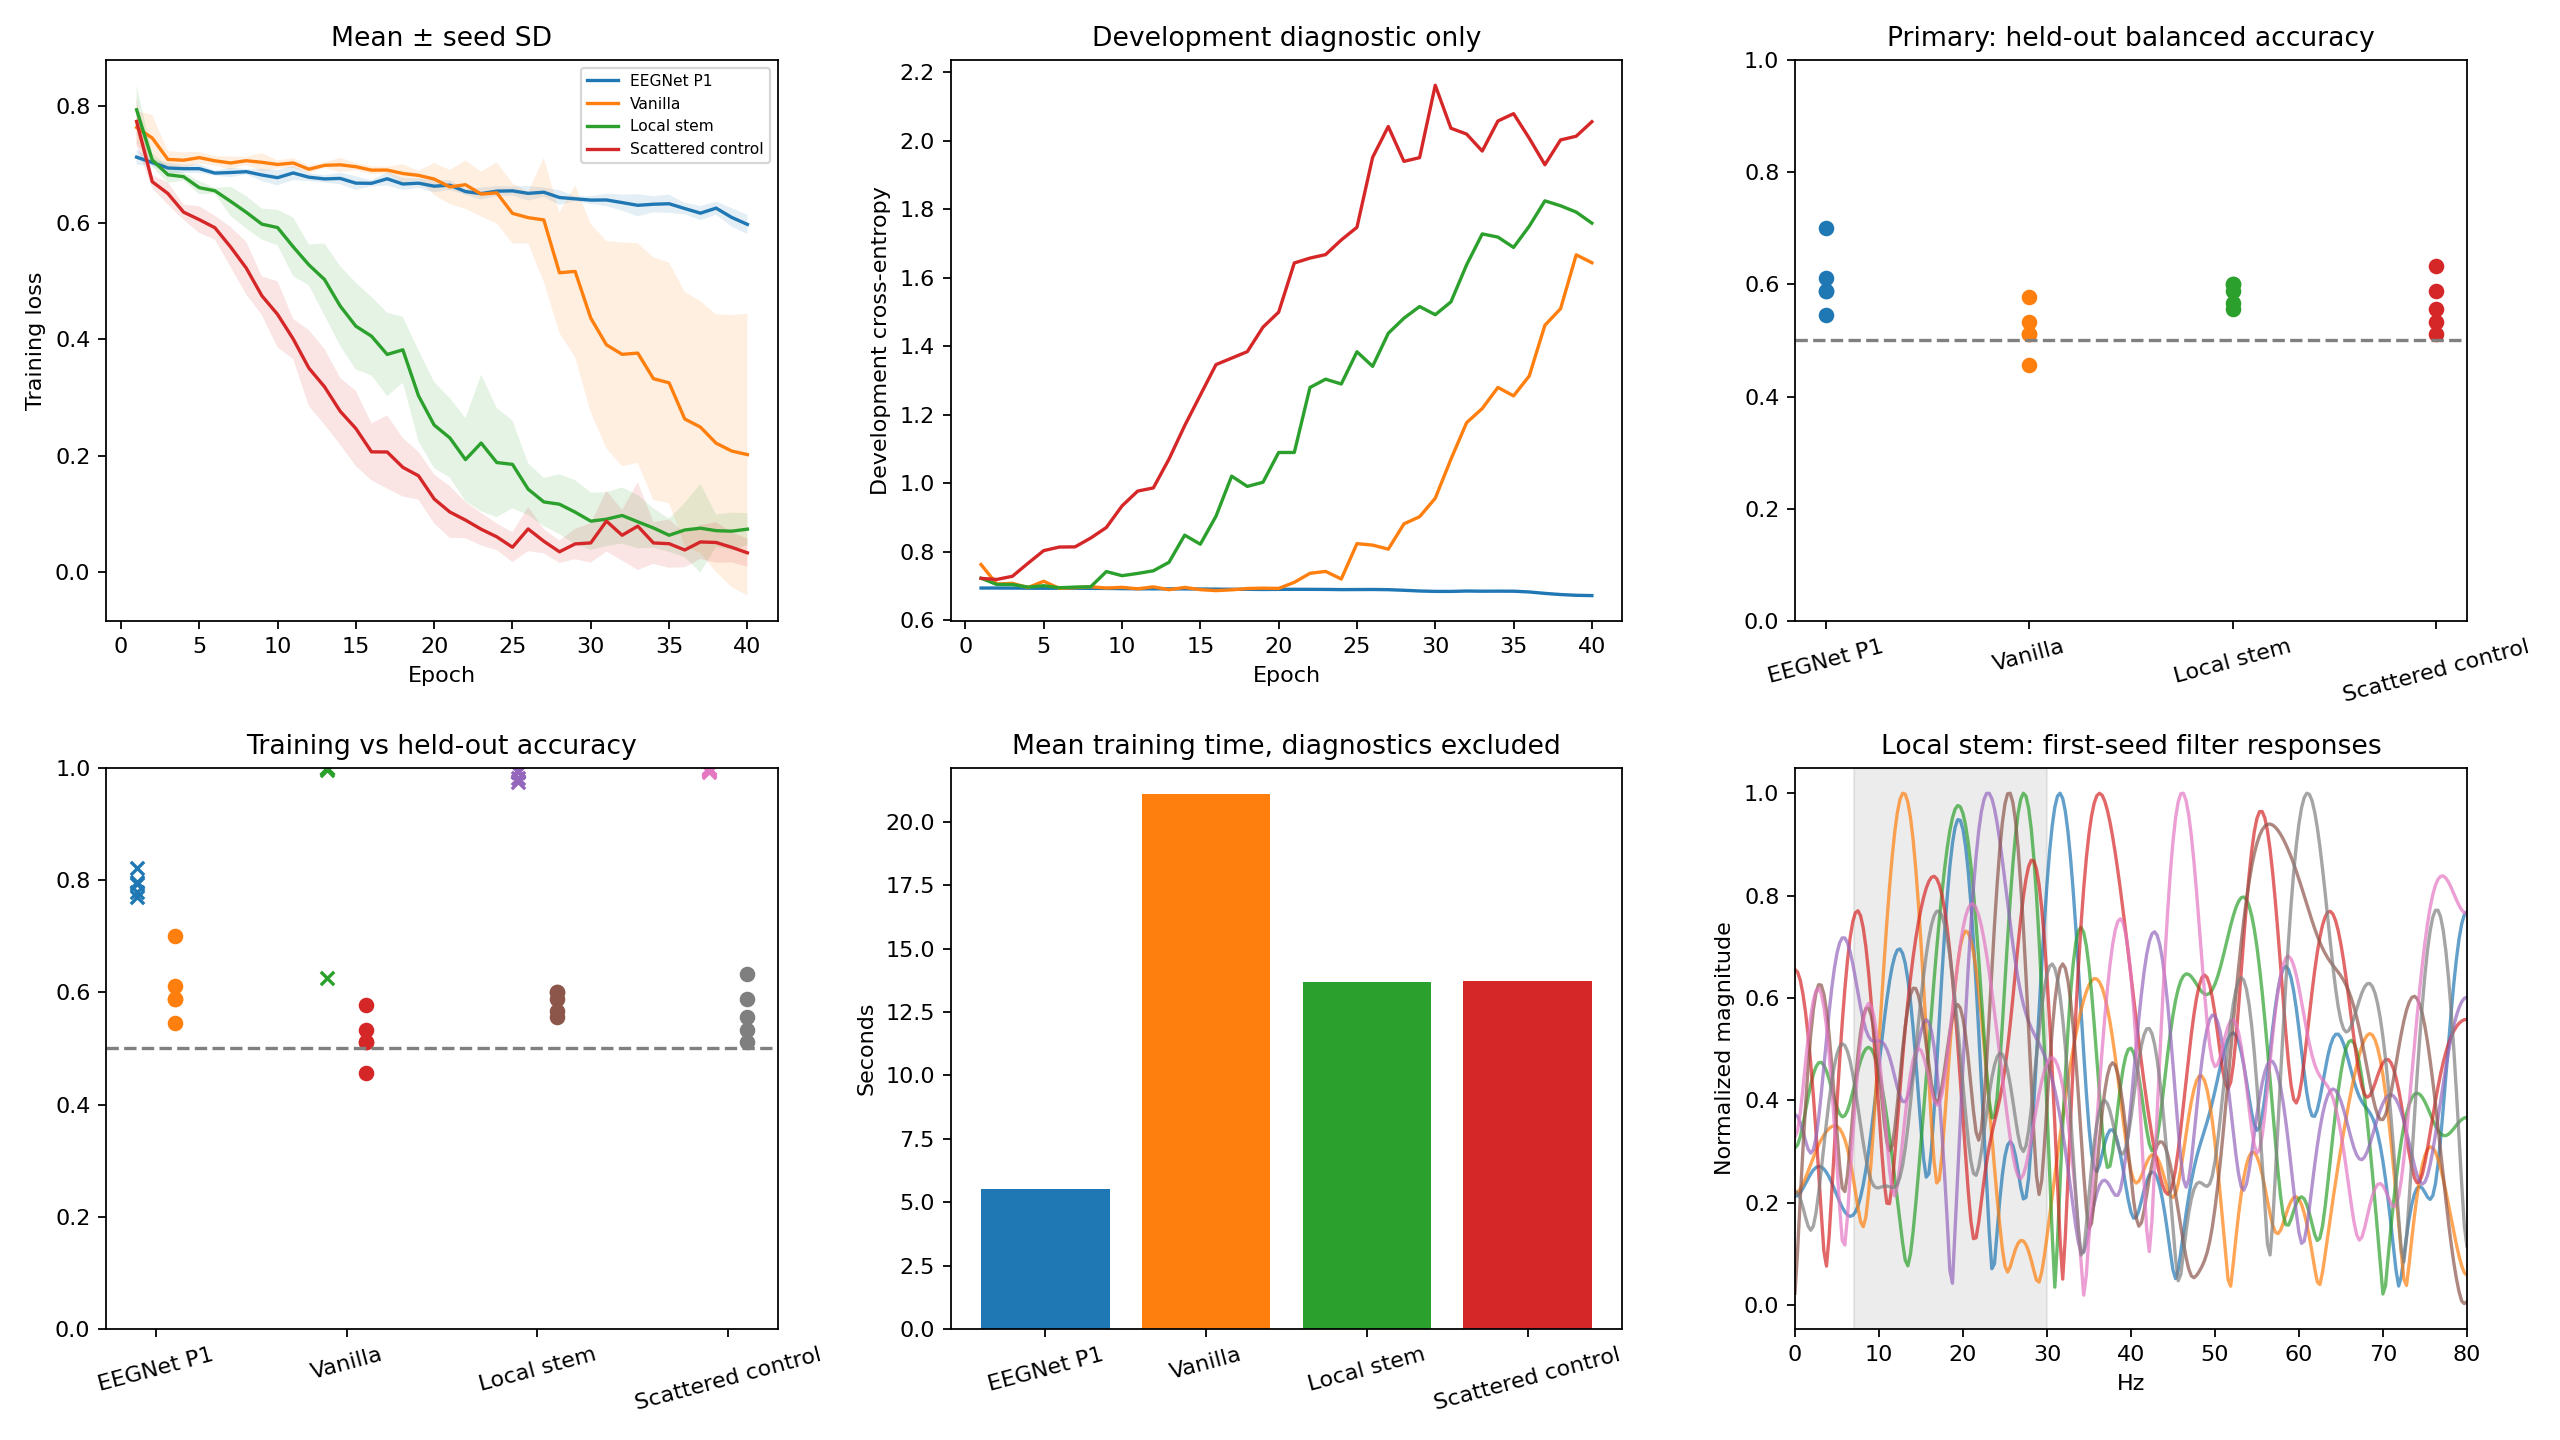

FINAL


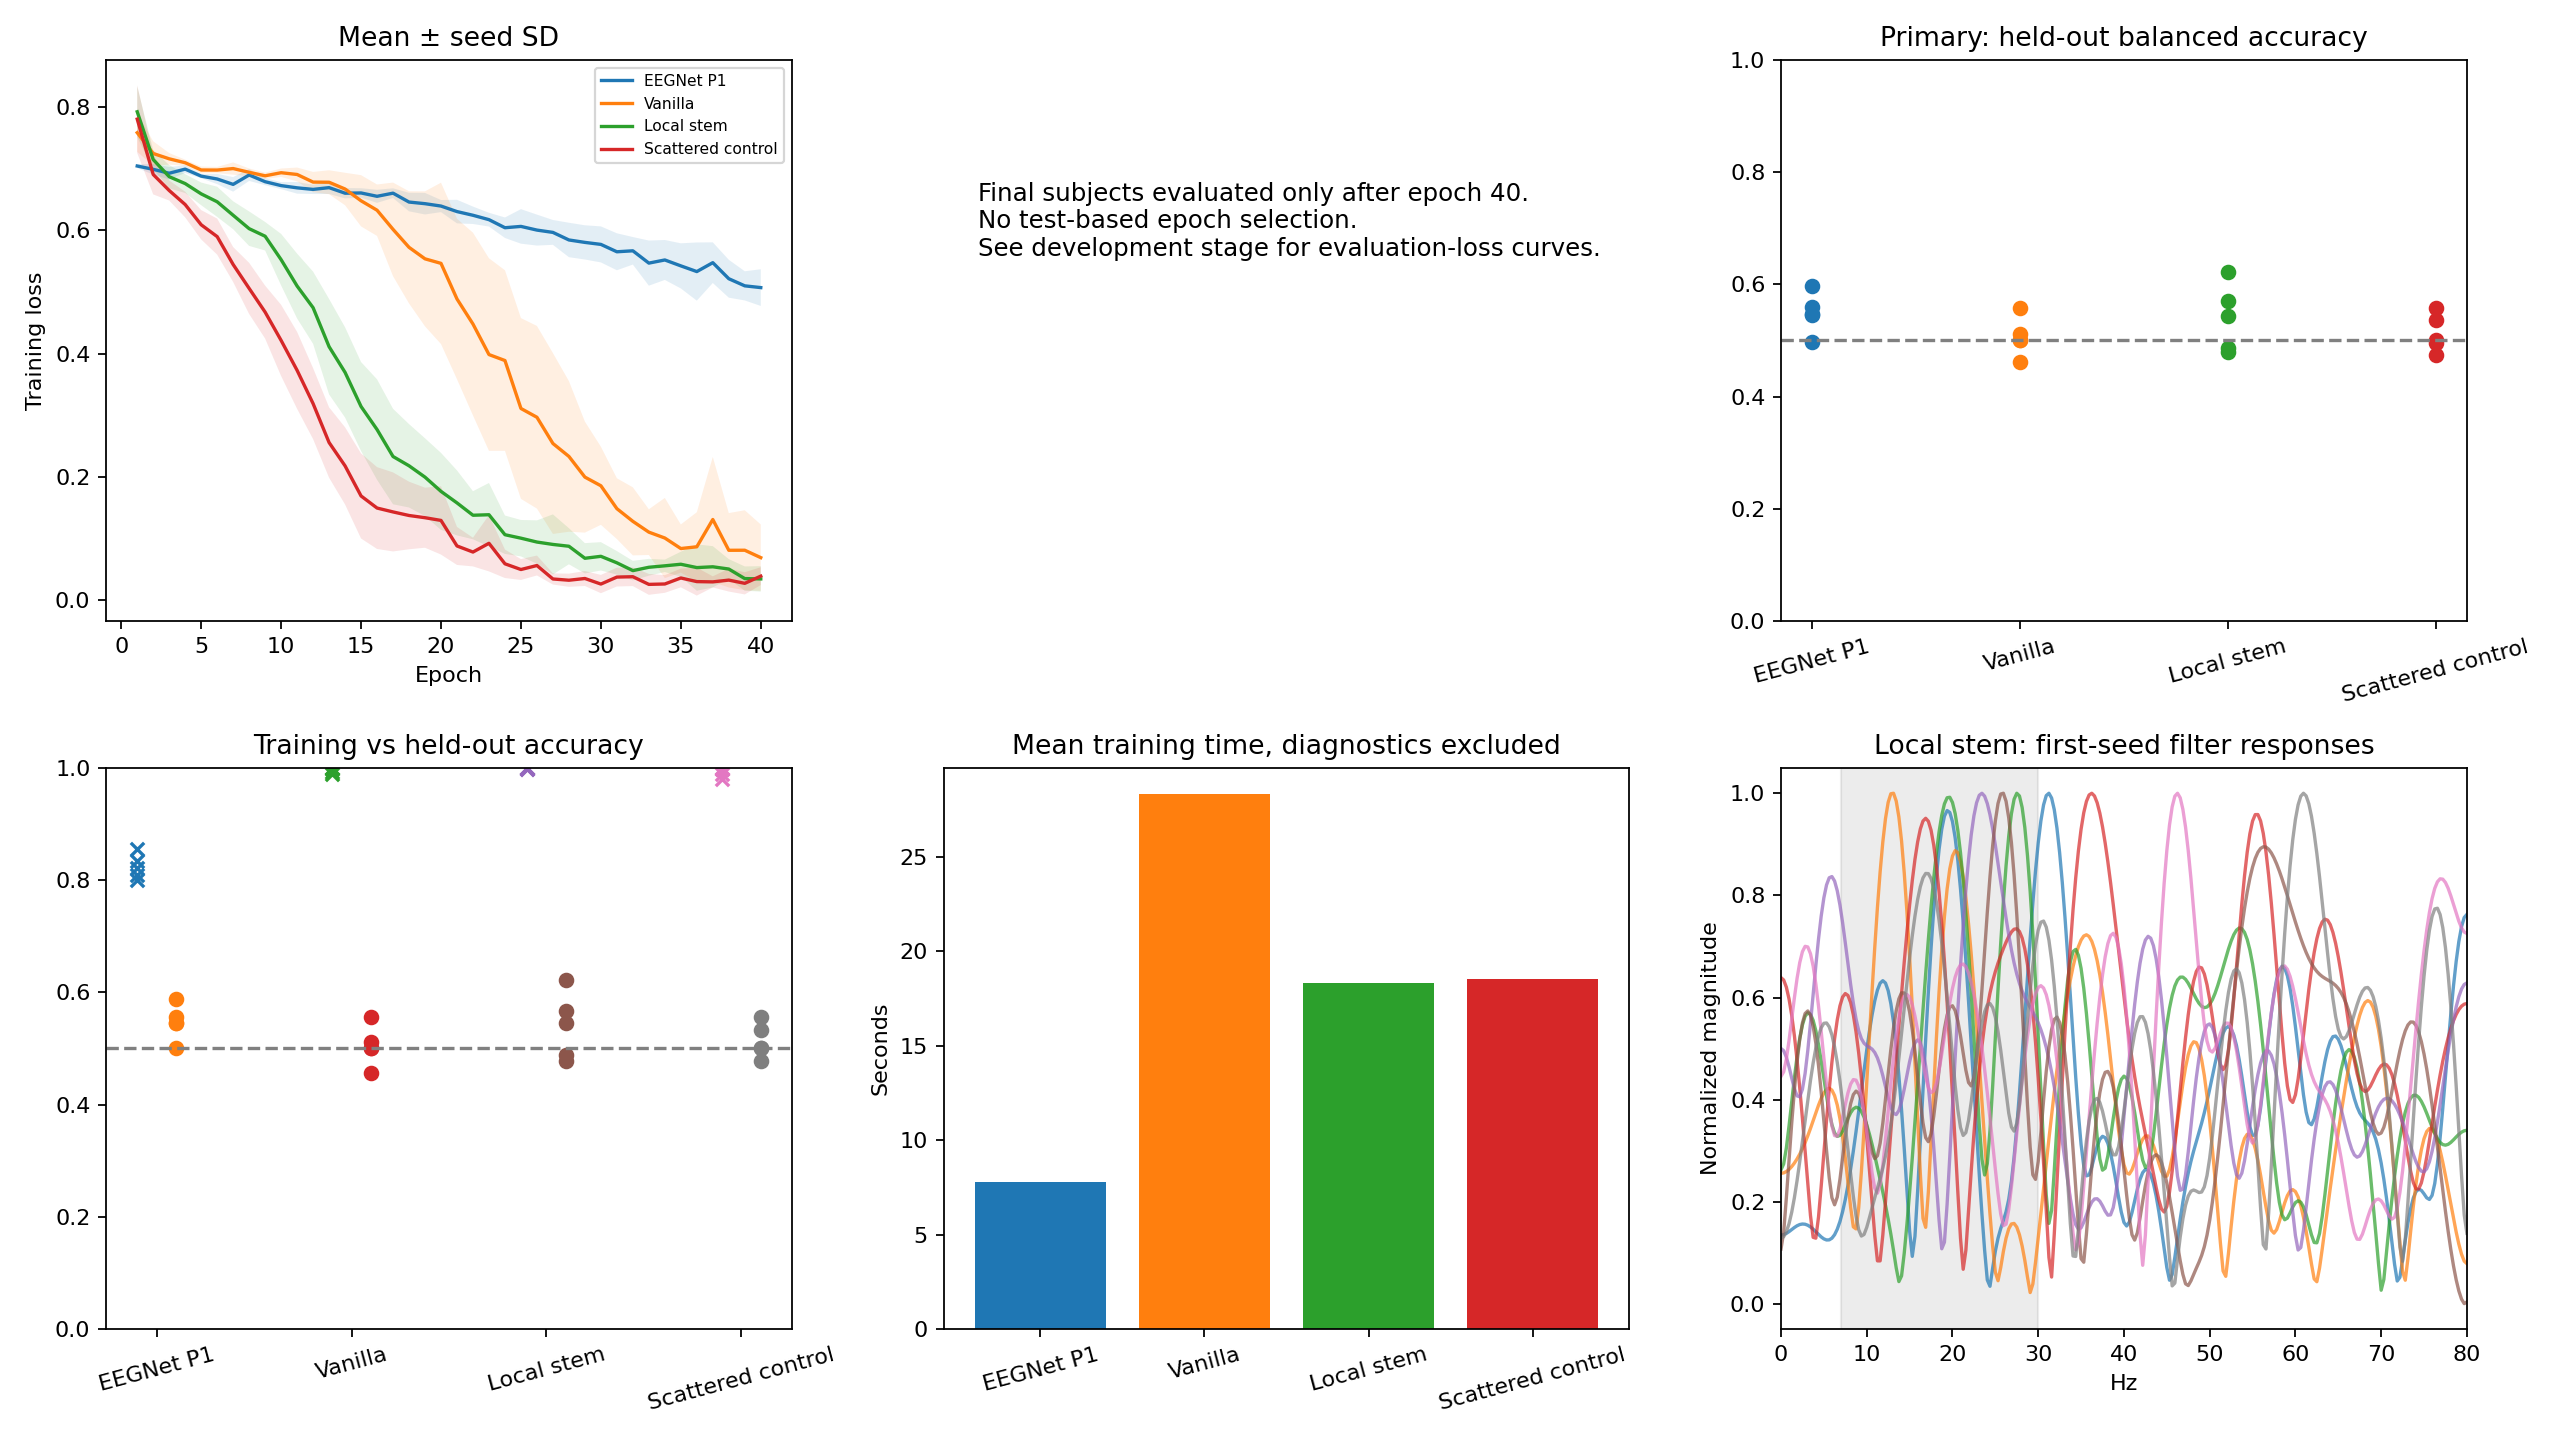

# Part 2 measured write-up draft

**Hypothesis (written before implementation):** Shared local temporal filters should reduce attention cost and improve held-out-subject balanced accuracy and seed stability relative to per-sample attention.

**Change and mechanism:** Eight learned 200 ms filters shared across all electrodes, stride 100 ms, produce 29 overlapping temporal tokens plus CLS. A learned spatial projection and the unchanged three-layer attention backbone follow. The vanilla and local models have the same 135,746 parameters. An equally sized scattered-time control tests ordered local grouping.

**Results:** Accuracy best / worst / mean = 62.22% / 47.78% / 54.00%. Balanced accuracy mean ± seed SD = 54.02% ± 5.32 pp. Full prespecified descriptive support: False. Inspect the report's individual criteria and controls before writing the interpretation; do not imply a significance test.

**Figure:** `figure.png` compares training losses, held-out scores, train/evaluation gaps and runtime, and shows the local model's first-seed learned temporal filter responses.

This was an exploratory follow-up after seeing baseline test results. Repeat checks, all seeds and subject-level results are retained. Add a short, evidence-based interpretation before submission.


Saved on Drive: /content/drive/MyDrive/Basil AI Intern OA/part2_transformer/artifacts/controlled_experiment/study_20261101T091133698074Z


In [7]:
from IPython.display import Image
runs = sorted((LOCAL_PART2 / 'artifacts').glob('study_*'))
completed = [p for p in runs if p.is_dir() and not p.name.startswith('study_smoke_')
             and (p / 'metadata.json').is_file()
             and json.loads((p / 'metadata.json').read_text()).get('status') == 'complete']
if not completed:
    raise RuntimeError('No completed real study. Check the training log.')
RUN_DIR = completed[-1]
display(Markdown((RUN_DIR / 'EXPERIMENT_REPORT.md').read_text()))
for stage in STAGES:
    print(stage.upper())
    display(Image(filename=str(RUN_DIR / stage / 'experiment_dashboard.png')))
if (RUN_DIR / 'ANSWER_DRAFT.md').exists():
    display(Markdown((RUN_DIR / 'ANSWER_DRAFT.md').read_text()))
print('Saved on Drive:', DRIVE_OUTPUTS / RUN_DIR.name)


## Export results
The ZIP includes the hypothesis snapshot, source hashes, hardware/software metadata, all seed results, paired control differences, exact-repeat checks, figures, checkpoints, and a measured write-up draft. Inspect and explain the actual outcome before using the draft in `ANSWERS.md`.

In [8]:
archive = Path(shutil.make_archive(str(LOCAL_PART2 / RUN_DIR.name), 'zip', root_dir=RUN_DIR))
DRIVE_EXPORT = DRIVE_OUTPUTS / archive.name
shutil.copy2(archive, DRIVE_EXPORT)
print('Export ZIP:', DRIVE_EXPORT)
DOWNLOAD_TO_LAPTOP = False
if DOWNLOAD_TO_LAPTOP:
    from google.colab import files
    files.download(str(archive))


Export ZIP: /content/drive/MyDrive/Basil AI Intern OA/part2_transformer/artifacts/controlled_experiment/study_20261101T091133698074Z.zip
